# Data generation 

I was thinking of starting with a **controlled synthetic dataset**, so we can use it later to explore causal inference, Bayesian uncertainty, explainability, and latent representation learning.

For example, imagine a machine where the **workload** affects both its operating **speed** and **energy consumption**. So, the question is: **If we deliberately change the operating speed, how much would the energy consumption actually change?**

Since we're generating the data, we know the underlying causal mechanism. This allows us to compare observational and interventional data, calculate the true causal effects, and verify the results mathematically.

Then, as we move forward, we can gradually introduce more complex conditions, like **hidden confounders, nonlinear relationships, latent variables, and distribution shifts**, and investigate how reliably different causal machine learning models perform under those conditions.


In [27]:
from pathlib import Path
import json
import sys
import jax
import jax.numpy as jnp
from jax import random
jax.config.update("jax_enable_x64", True)
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", context="notebook")
OUTPUT = Path("jax_outputs")  # Separate folder avoids overwriting original NumPy CSV files
FIGURES = OUTPUT / "figures"
DATA = OUTPUT / "data"
FIGURES.mkdir(parents=True, exist_ok=True)
DATA.mkdir(parents=True, exist_ok=True)
print("Python:", sys.version.split()[0])
print("JAX:", jax.__version__, "pandas:", pd.__version__)
print("JAX device:", jax.devices()[0])

def assert_allclose(actual, expected, rtol=1e-12, atol=1e-12):
    assert bool(jnp.allclose(jnp.asarray(actual), jnp.asarray(expected), rtol=rtol, atol=atol)), "Arrays differ beyond tolerance"

Python: 3.12.3
JAX: 0.12.0.1 pandas: 2.3.2
JAX device: cpu:0


## Our causal graph 

Three variables are involved:

- **\(U\)** — workload, measured *before* speed is selected. It is an **observed confounder**, because it affects both speed and energy use.
- **\(X\)** — operating speed, the variable an operator can deliberately set (the *treatment*).
- **\(Y\)** — energy consumption, the outcome.

Our **directed acyclic graph (DAG)** is,

```text
             U (workload)
            /            \\
           v              v
     X (speed)  -------> Y (energy)
```

The arrows are **assumed by design** because we generate the data. They are not discovered from the observed correlations.

A confounder creates a path $X \leftarrow U \rightarrow Y$, so observing high energy usage at high speed does not, by itself, tell us the effect of *setting* speed higher.

## Structural Causal Model (SCM)

A **Structural Causal Model** specifies each variable as a function of its causal parents and an external noise variable. For environment \(e\), we choose,

$$
U \sim \mathcal{N}(\mu_e, \sigma_e^2), \quad
\epsilon_X \sim \mathcal{N}(0,1), \quad
\epsilon_Y \sim \mathcal{N}(0,1)
$$

$$
X = 0.8U + \epsilon_X, \qquad
Y = 2X + 1.5U + 0.5XU + \epsilon_Y
$$

Here $\mathcal{N}(\mu, \sigma^2)$ means a **normal (Gaussian) distribution**, with mean $\mu$ and variance $\sigma^2$. All three exogenous random sources are mutually independent. This independence is one of our deliberate assumptions.

**Why each term**

- \(0.8U\) makes workload influence speed, producing confounding.
- \(2X\) is the direct baseline effect of speed on energy use.
- \(1.5U\) lets workload affect energy consumption independently of speed.
- \(0.5XU\) is an **interaction**: the speed effect changes with workload (heterogeneous treatment effect).
- The two noise terms create imperfect, more realistic observations without changing our known causal mechanism.

These coefficients are chosen to make an interpretable teaching/research benchmark.


In [2]:
PARAMETERS = {"speed_from_load": 0.8, "speed_effect": 2.0,
              "load_effect": 1.5, "interaction": 0.5,
              "speed_noise_sd": 1.0, "outcome_noise_sd": 1.0}
ENVIRONMENTS = {"A": {"load_mean": 0.0, "load_sd": 1.0},
                "B": {"load_mean": 2.0, "load_sd": 1.0}}

def structural_outcome(x, u, eps_y):
    """Y equation; x, u, eps_y may be scalars or compatible arrays."""
    x, u, eps_y = jnp.asarray(x), jnp.asarray(u), jnp.asarray(eps_y)
    return (PARAMETERS["speed_effect"] * x
            + PARAMETERS["load_effect"] * u
            + PARAMETERS["interaction"] * x * u + eps_y)

def true_individual_effect(u, x0=0.0, x1=1.0):
    """Y(x1)-Y(x0) with same U and same exogenous outcome noise."""
    return (x1 - x0) * (PARAMETERS["speed_effect"]
                        + PARAMETERS["interaction"] * jnp.asarray(u))

def true_population_ate(env, x0=0.0, x1=1.0):
    return float((x1 - x0) * (PARAMETERS["speed_effect"]
                             + PARAMETERS["interaction"] * ENVIRONMENTS[env]["load_mean"]))

print("True ATE, environment A:", true_population_ate("A"))
print("True ATE, environment B:", true_population_ate("B"))

True ATE, environment A: 2.0
True ATE, environment B: 3.0


## Generate data


**Observational data** are collected under the natural speed-setting policy $X=0.8U+\epsilon_X$. We do not force $X$ to a value here.

Causal benchmark separates two kinds of columns,

- **Learner-facing columns:** `U`, `X`, `Y`, which a future model may access.
- **Oracle / audit columns:** random disturbances and counterfactual outcomes, available only to us because we wrote the simulator. 

The two potential outcomes are created using **the same workload and the same outcome disturbance**,

$$
Y(0)=1.5U+\epsilon_Y,\qquad
Y(1)=2+1.5U+0.5U+\epsilon_Y.
$$

Thus $Y(1)-Y(0)=2+0.5U$. This shared-noise construction is what makes the individual-level contrast unambiguous *inside our chosen SCM*.


In [3]:
def generate_observational(n, environment="A", seed=2026):
    if environment not in ENVIRONMENTS:
        raise ValueError(f"Unknown environment: {environment}")
    if not isinstance(n, int) or n < 1:
        raise ValueError("n must be a positive integer")
    key = random.PRNGKey(seed)
    key_u, key_x, key_y = random.split(key, 3)
    cfg = ENVIRONMENTS[environment]
    u = cfg["load_mean"] + cfg["load_sd"] * random.normal(key_u, (n,), dtype=jnp.float64)
    eps_x = PARAMETERS["speed_noise_sd"] * random.normal(key_x, (n,), dtype=jnp.float64)
    eps_y = PARAMETERS["outcome_noise_sd"] * random.normal(key_y, (n,), dtype=jnp.float64)
    x = PARAMETERS["speed_from_load"] * u + eps_x
    y = structural_outcome(x, u, eps_y)
    y0 = structural_outcome(0.0, u, eps_y)
    y1 = structural_outcome(1.0, u, eps_y)
    frame = pd.DataFrame({"U": u, "X": x, "Y": y,
                          "epsilon_X": eps_x, "epsilon_Y": eps_y,
                          "Y0": y0, "Y1": y1,
                          "tau_true": y1 - y0})
    return frame

example = generate_observational(500, "A", seed=1101)
print("Shape:", example.shape)
display(example.head(8).round(3))

Shape: (500, 8)


,U,X,Y,epsilon_X,epsilon_Y,Y0,Y1,tau_true
0,0.035,1.476,2.315,1.448,-0.716,-0.664,1.353,2.017
1,-0.302,-1.353,-3.101,-1.111,-0.147,-0.600,1.249,1.849
2,0.225,0.356,0.123,0.176,-0.967,-0.629,1.483,2.112
3,-0.532,0.823,0.086,1.249,-0.542,-1.341,0.393,1.734
4,-0.524,0.153,1.698,0.572,2.219,1.433,3.171,1.738
5,0.669,1.074,2.371,0.538,-1.140,-0.136,2.198,2.335
6,0.847,1.019,5.486,0.342,1.746,3.017,5.440,2.423
7,0.142,-1.176,-0.989,-1.289,1.234,1.447,3.518,2.071



## Verify the generator

Synthetic data are useful only when the implementation actually matches the stated equations. We use **assertions** (tests that stop execution if an expected identity fails) to check:

1. The factual outcome $Y$ equals the structural equation.
2. The stored potential outcomes equal $Y$ evaluated under forced speed 0 and 1, respectively.
3. The individual treatment effect equals $2+0.5U$.
4. Repeating the same seed reproduces identical data.
5. Changing the seed produces different draws.

These are **implementation checks**.


In [4]:
calculated_y = structural_outcome(example["X"], example["U"], example["epsilon_Y"])
assert_allclose(example["Y"], calculated_y, rtol=1e-12, atol=1e-12)
assert_allclose(example["Y0"], structural_outcome(0, example["U"], example["epsilon_Y"]))
assert_allclose(example["Y1"], structural_outcome(1, example["U"], example["epsilon_Y"]))
assert_allclose(example["tau_true"], true_individual_effect(example["U"]))
pd.testing.assert_frame_equal(example, generate_observational(500, "A", 1101))
assert not example.equals(generate_observational(500, "A", 1102))
print("PASS: Structural equations, potential outcomes, effects, and reproducibility")
print("Maximum individual-effect identity error:",
      float(jnp.abs(jnp.asarray(example["tau_true"]) - true_individual_effect(example["U"])).max()))

PASS: Structural equations, potential outcomes, effects, and reproducibility
Maximum individual-effect identity error: 8.881784197001252e-16


## Examine the observational distribution

- **Histograms** - the marginal distribution.
- **Scatter plot** - speed versus energy reveals observational association.
- **Correlation matrix** - linear association.

The plots below use 2,000 observational samples from Environment A.

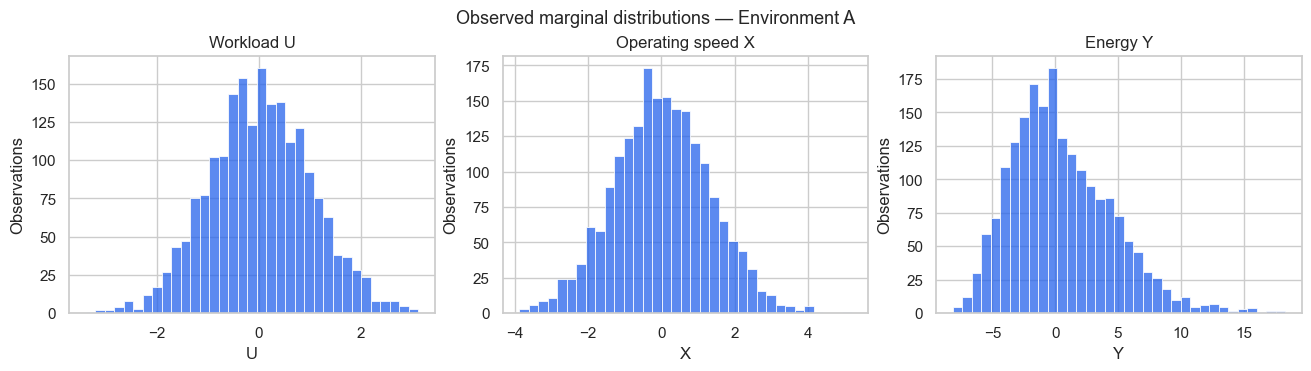

In [5]:
viz = generate_observational(2_000, "A", seed=1201)
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6), constrained_layout=True)
for ax, col, label in zip(axes, ["U", "X", "Y"],
                          ["Workload U", "Operating speed X", "Energy Y"]):
    sns.histplot(viz[col], bins=35, ax=ax, color="#2563eb", edgecolor="white")
    ax.set_title(label)
    ax.set_xlabel(col)
    ax.set_ylabel("Observations")
fig.suptitle("Observed marginal distributions — Environment A", fontsize=13)
fig.savefig(FIGURES / "01_marginal_distributions.png", dpi=160, bbox_inches="tight")
plt.show()

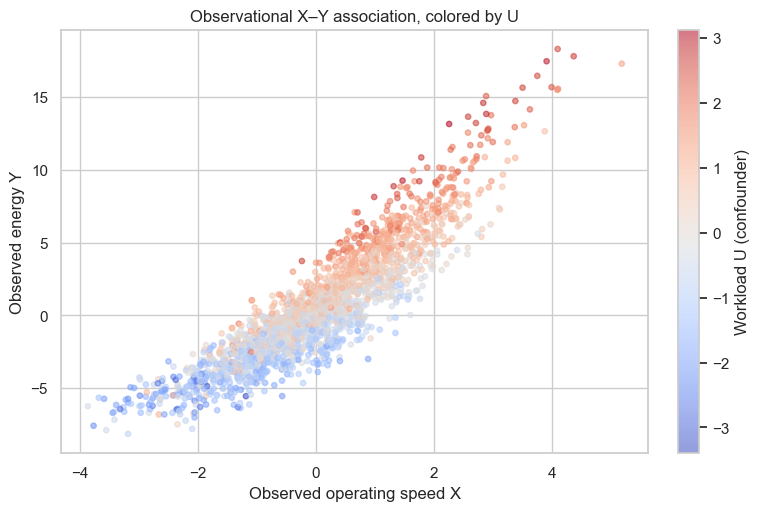

In [6]:
fig, ax = plt.subplots(figsize=(7.5, 5), constrained_layout=True)
sc = ax.scatter(viz["X"], viz["Y"], c=viz["U"], cmap="coolwarm", s=15, alpha=0.55)
fig.colorbar(sc, ax=ax, label="Workload U (confounder)")
ax.set(xlabel="Observed operating speed X", ylabel="Observed energy Y",
       title="Observational X–Y association, colored by U")
fig.savefig(FIGURES / "02_observational_scatter.png", dpi=160, bbox_inches="tight")
plt.show()

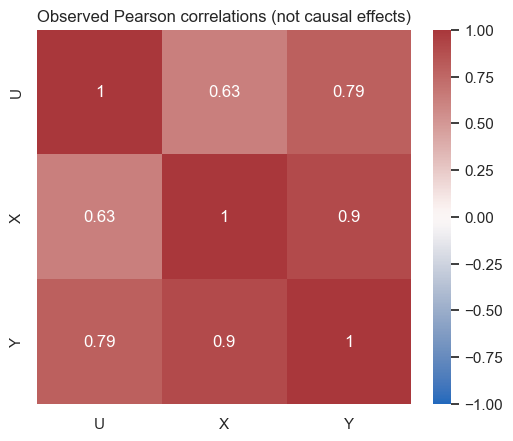

,U,X,Y
U,1.000,0.626,0.790
X,0.626,1.000,0.904
Y,0.790,0.904,1.000


In [7]:
corr = viz[["U", "X", "Y"]].corr()
fig, ax = plt.subplots(figsize=(5.3, 4.3), constrained_layout=True)
sns.heatmap(corr, annot=True, vmin=-1, vmax=1, cmap="vlag", square=True, ax=ax)
ax.set_title("Observed Pearson correlations (not causal effects)")
fig.savefig(FIGURES / "03_correlations.png", dpi=160, bbox_inches="tight")
plt.show()
display(corr.round(3))


## Derive the exact effect of an intervention

An intervention $do(X=x)$ replaces the natural speed equation with the constant $X:=x$. It **cuts the arrow from workload to speed**, but keeps the outcome mechanism unchanged.

The resulting outcome is,

$$
Y\mid do(X=x)=2x+1.5U+0.5xU+\epsilon_Y.
$$

Averaging over the environment's workload distribution and zero-mean noise gives,

$$
\boxed{\mathbb{E}[Y\mid do(X=x)] = 2x + (1.5+0.5x)\mu_e.}
$$

For Environment A, $\mu_A=0$, so the response is $2x$. For Environment B, $\mu_B=2$, it is $3x+3$.

Changing speed from 0 to 1 gives,

$$
\underbrace{Y(1)-Y(0)}_{\mathrm{ITE}}=2+0.5U,
\qquad
\underbrace{\mathbb{E}[Y(1)-Y(0)]}_{\mathrm{ATE}}=2+0.5\mu_e.
$$

**ITE** = Individual Treatment Effect; **ATE** = Average Treatment Effect; **CATE** = Conditional Average Treatment Effect. Here, conditional on workload, $\mathrm{CATE}(u)=2+0.5u$. The exact ITE is known only because this synthetic structural equation specifies the same background disturbances across interventions.


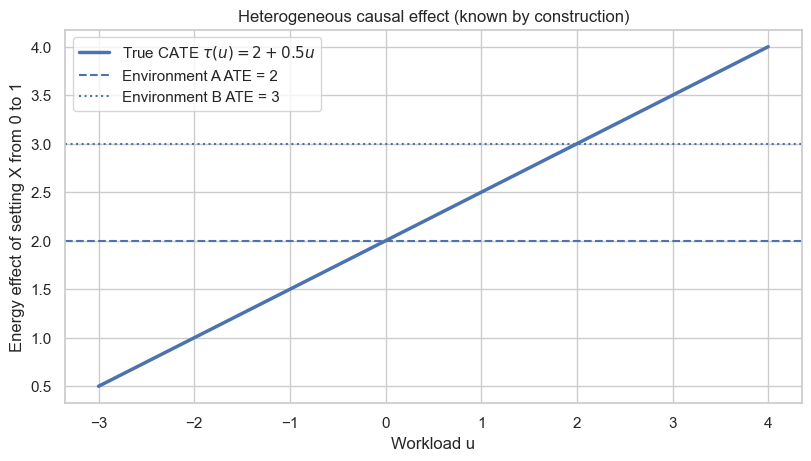

In [8]:
def interventional_mean(x, environment):
    mu = ENVIRONMENTS[environment]["load_mean"]
    return 2 * jnp.asarray(x) + (1.5 + 0.5 * jnp.asarray(x)) * mu

u_grid = jnp.linspace(-3, 4, 200)
fig, ax = plt.subplots(figsize=(8, 4.5), constrained_layout=True)
ax.plot(u_grid, true_individual_effect(u_grid), label=r"True CATE $\tau(u)=2+0.5u$", lw=2.5)
ax.axhline(true_population_ate("A"), ls="--", label="Environment A ATE = 2")
ax.axhline(true_population_ate("B"), ls=":", label="Environment B ATE = 3")
ax.set(xlabel="Workload u", ylabel="Energy effect of setting X from 0 to 1",
       title="Heterogeneous causal effect (known by construction)")
ax.legend()
fig.savefig(FIGURES / "04_true_causal_effect.png", dpi=160, bbox_inches="tight")
plt.show()


## Observational prediction

In Environment A,

$$
U\sim\mathcal{N}(0,1),\quad X=0.8U+\epsilon_X,
\quad \operatorname{Var}(X)=0.8^2+1=1.64.
$$

Because $(U,X)$ is jointly Gaussian,

$$
\mathbb{E}[U\mid X=x]
=\frac{\operatorname{Cov}(U,X)}{\operatorname{Var}(X)}x
=\frac{0.8}{1.64}x=\frac{20}{41}x.
$$

Substitute this into the outcome equation, using $\mathbb{E}[\epsilon_Y\mid X]=0$,

$$
\begin{aligned}
\mathbb{E}[Y\mid X=x]
&=2x+(1.5+0.5x)\mathbb{E}[U\mid X=x]\\
&=\boxed{\frac{112}{41}x+\frac{10}{41}x^2}.
\end{aligned}
$$

Therefore, **setting** speed by intervention yields $\mathbb{E}[Y\mid do(X=x)]=2x$ for Environment A.

Conditioning on observed speed also selects machines with different likely workload. Intervening on speed does *not* change the workload distribution. Therefore these two questions have different answers even with unlimited observational data.


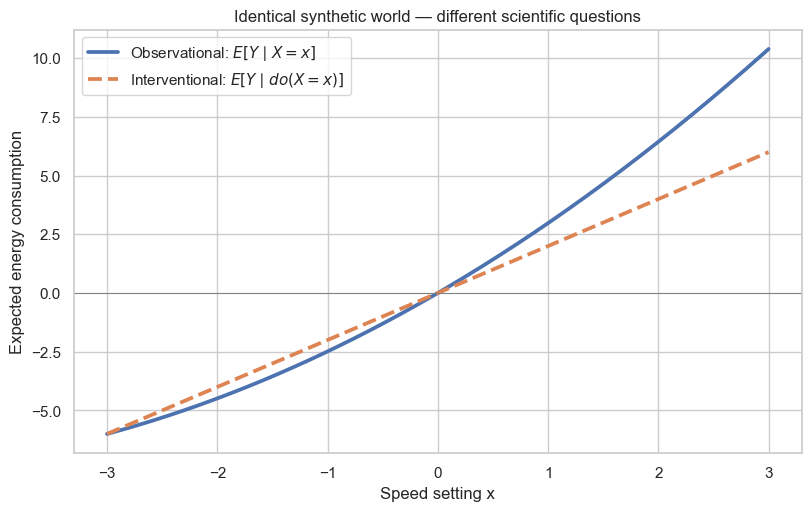

At x=1: observational expectation = 2.9756
At x=1: intervention expectation = 2.0


In [9]:
def observational_mean_env_a(x):
    x = jnp.asarray(x)
    return (112.0 / 41.0) * x + (10.0 / 41.0) * x**2

x_grid = jnp.linspace(-3, 3, 300)
fig, ax = plt.subplots(figsize=(8, 5), constrained_layout=True)
ax.plot(x_grid, observational_mean_env_a(x_grid), lw=2.7,
        label=r"Observational: $E[Y\mid X=x]$")
ax.plot(x_grid, interventional_mean(x_grid, "A"), lw=2.7, ls="--",
        label=r"Interventional: $E[Y\mid do(X=x)]$")
ax.axhline(0, lw=0.7, color="gray")
ax.set(xlabel="Speed setting x", ylabel="Expected energy consumption",
       title="Identical synthetic world — different scientific questions")
ax.legend()
fig.savefig(FIGURES / "05_observational_vs_interventional.png", dpi=180, bbox_inches="tight")
plt.show()
print("At x=1: observational expectation =", round(float(observational_mean_env_a(1)), 4))
print("At x=1: intervention expectation =", round(float(interventional_mean(1, "A")), 4))


## Generate actual randomized intervention data

The formulas above are *analytic*. We also want to simulate interventions explicitly to confirm them independently.

When we run a randomized intervention, we sample workload and outcome noise as usual, but do not use the natural equation for speed. Instead we set $X=x$ for everyone.

Observational rows and intervention rows are kept in separate files, so later models cannot accidentally confuse data from distinct regimes.


In [10]:
def generate_intervention(n, environment="A", do_x=0.0, seed=2026):
    key_u, key_y = random.split(random.PRNGKey(seed))
    cfg = ENVIRONMENTS[environment]
    u = cfg["load_mean"] + cfg["load_sd"] * random.normal(key_u, (n,), dtype=jnp.float64)
    eps_y = PARAMETERS["outcome_noise_sd"] * random.normal(key_y, (n,), dtype=jnp.float64)
    x = jnp.full(n, float(do_x))
    y = structural_outcome(x, u, eps_y)
    return pd.DataFrame({"U": u, "X": x, "Y": y,
                         "regime": f"do(X={do_x:g})"})

rows = []
for env in ENVIRONMENTS:
    for do_x in (0.0, 1.0):
        trial = generate_intervention(30_000, env, do_x, seed=9000 + int(do_x) + (100 if env == "B" else 0))
        empirical = float(trial["Y"].mean())
        exact = float(interventional_mean(do_x, env))
        rows.append({"environment": env, "intervention": f"do(X={do_x:g})",
                     "simulated_mean": empirical, "theoretical_mean": exact,
                     "absolute_MC_error": abs(empirical - exact)})
summary = pd.DataFrame(rows)
display(summary.round(4))
assert summary["absolute_MC_error"].max() < 0.08, "Unexpectedly large Monte Carlo discrepancy"
print("PASS: Randomized intervention means agree with theoretical means to sampling accuracy")

,environment,intervention,simulated_mean,theoretical_mean,absolute_MC_error
0,A,do(X=0),0.0036,0.0,0.0036
1,A,do(X=1),1.9973,2.0,0.0027
2,B,do(X=0),2.9788,3.0,0.0212
3,B,do(X=1),5.9915,6.0,0.0085


PASS: Randomized intervention means agree with theoretical means to sampling accuracy



## Compare environments without changing the underlying causal law

**Environment A:** $U\sim\mathcal{N}(0,1)$.  
**Environment B:** $U\sim\mathcal{N}(2,1)$.

We change only the *distribution of workload*, not the structural equations for speed or energy. This is a **population/distribution shift**, not a change to the outcome mechanism.

Because the effect $2+0.5U$ depends on workload, the **population ATE** changes even though the underlying effect function $\tau(u)$ is unchanged:

- Environment A: ATE = 2.
- Environment B: ATE = 3.

Later, this will allow us to ask whether a model trained in one environment can correctly estimate effects in another. We are **not yet testing a fitted model**.


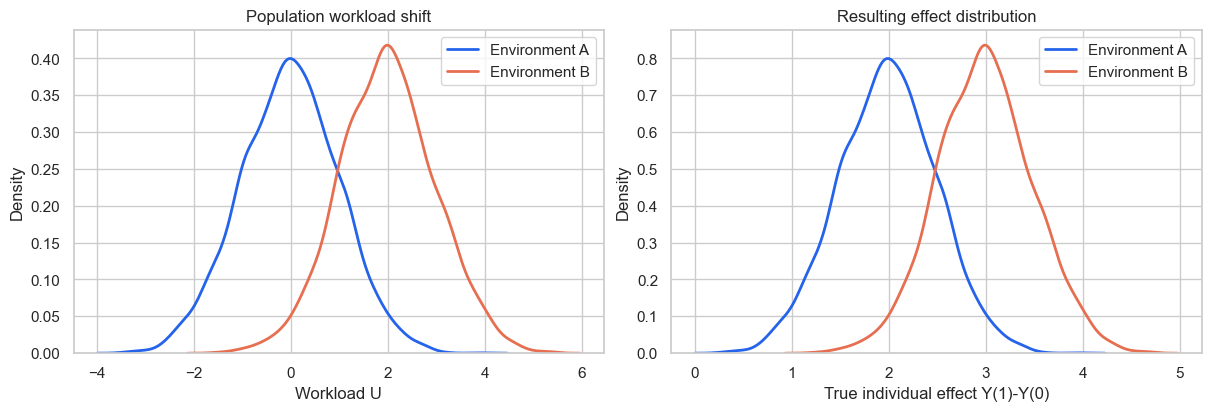

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), constrained_layout=True)
for env, color in (("A", "#2563eb"), ("B", "#e76f51")):
    d = generate_observational(5_000, env, seed=1301 if env == "A" else 1302)
    sns.kdeplot(d["U"], ax=axes[0], label=f"Environment {env}", color=color, lw=2)
    sns.kdeplot(d["tau_true"], ax=axes[1], label=f"Environment {env}", color=color, lw=2)
axes[0].set(xlabel="Workload U", title="Population workload shift")
axes[1].set(xlabel="True individual effect Y(1)-Y(0)", title="Resulting effect distribution")
for ax in axes: ax.legend()
fig.savefig(FIGURES / "06_environment_shift.png", dpi=160, bbox_inches="tight")
plt.show()


## Create reproducible training, validation, and test files

We use three sample sizes $n\in\{500,2000,10000\}$ **per environment**. For each, we independently generate:

- `train`: $n$ rows;
- `validation`: $\max(200,\lfloor0.2n\rfloor)$ rows;
- `test`: $\max(300,\lfloor0.3n\rfloor)$ rows.

These are **independent samples**, not random slices of one generated table. Seeds are constructed deterministically and recorded. We save:

- `*_observed.csv` — ONLY `U, X, Y` for downstream learning;
- `*_oracle.csv` — all columns including disturbances and ground-truth potential outcomes for evaluation only.


In [12]:
SAMPLE_SIZES = (500, 2_000, 10_000)
SPLITS = ("train", "validation", "test")
SEED_BASE = 20261026
manifest = []

for env_i, env in enumerate(ENVIRONMENTS):
    for size_i, train_n in enumerate(SAMPLE_SIZES):
        counts = {"train": train_n,
                  "validation": max(200, int(train_n * 0.2)),
                  "test": max(300, int(train_n * 0.3))}
        for split_i, split in enumerate(SPLITS):
            seed = SEED_BASE + env_i * 100_000 + size_i * 10_000 + split_i * 1_000
            df = generate_observational(counts[split], env, seed)
            stem = f"env_{env}_n{train_n}_{split}"
            observed_path = DATA / f"{stem}_observed.csv"
            oracle_path = DATA / f"{stem}_oracle.csv"
            df[["U", "X", "Y"]].to_csv(observed_path, index=False)
            df.to_csv(oracle_path, index=False)
            manifest.append({"environment": env, "training_sample_size": train_n,
                             "split": split, "rows": len(df), "seed": seed,
                             "observed_file": observed_path.name,
                             "oracle_file": oracle_path.name})

manifest_df = pd.DataFrame(manifest)
display(manifest_df.head(9))
print("Observational CSV files:", len(manifest) * 2)

,environment,training_sample_size,split,rows,seed,observed_file,oracle_file
0,A,500,train,500,20261026,env_A_n500_train_observed.csv,env_A_n500_train_oracle.csv
1,A,500,validation,200,20262026,env_A_n500_validation_observed.csv,env_A_n500_validation_oracle.csv
2,A,500,test,300,20263026,env_A_n500_test_observed.csv,env_A_n500_test_oracle.csv
3,A,2000,train,2000,20271026,env_A_n2000_train_observed.csv,env_A_n2000_train_oracle.csv
4,A,2000,validation,400,20272026,env_A_n2000_validation_observed.csv,env_A_n2000_validation_oracle.csv
5,A,2000,test,600,20273026,env_A_n2000_test_observed.csv,env_A_n2000_test_oracle.csv
6,A,10000,train,10000,20281026,env_A_n10000_train_observed.csv,env_A_n10000_train_oracle.csv
7,A,10000,validation,2000,20282026,env_A_n10000_validation_observed.csv,env_A_n10000_validation_oracle.csv
8,A,10000,test,3000,20283026,env_A_n10000_test_observed.csv,env_A_n10000_test_oracle.csv


Observational CSV files: 36



## Save intervention test sets

We also save intervention datasets at $X=0$ and $X=1$ for each environment. These are kept out of the observational training files, and they can later be used as an explicit external evaluation regime.


In [13]:
intervention_manifest = []
for env_i, env in enumerate(ENVIRONMENTS):
    for intervention_i, do_x in enumerate((0.0, 1.0)):
        seed = SEED_BASE + 500_000 + env_i * 10_000 + intervention_i * 1_000
        intervention_df = generate_intervention(10_000, env, do_x, seed)
        name = f"env_{env}_do_X_{int(do_x)}_test.csv"
        intervention_df.to_csv(DATA / name, index=False)
        intervention_manifest.append({"environment": env, "do_x": do_x,
                                      "rows": len(intervention_df), "seed": seed, "file": name})
metadata = {"study": "Synthetic causal machine benchmark V1 (JAX implementation)",
            "random_backend": "jax.random; three independent split keys for observational U, epsilon_X, epsilon_Y",
            "parameter_values": PARAMETERS,
            "environments": ENVIRONMENTS,
            "independence": "U, epsilon_X, epsilon_Y generated independently",
            "causal_graph_edges": [["U", "X"], ["U", "Y"], ["X", "Y"]],
            "outcome_equation": "Y = 2 X + 1.5 U + 0.5 X U + epsilon_Y",
            "speed_equation": "X = 0.8 U + epsilon_X",
            "true_ite_0_to_1": "2 + 0.5 U",
            "true_ate_0_to_1": {e: true_population_ate(e) for e in ENVIRONMENTS},
            "observational_splits": manifest,
            "intervention_tests": intervention_manifest,
            "learner_columns": ["U", "X", "Y"],
            "oracle_only_columns": ["epsilon_X", "epsilon_Y", "Y0", "Y1", "tau_true"],
            "limitations": ["Abstract standardized units", "Observed confounder only",
                            "Simple polynomial mechanisms", "Normal independent disturbances",
                            "Not real machine measurements"]}
with open(OUTPUT / "metadata.json", "w", encoding="utf-8") as f:
    json.dump(metadata, f, indent=2)
manifest_df.to_csv(OUTPUT / "dataset_manifest.csv", index=False)
print("Saved metadata.json and dataset_manifest.csv")
print("Files in data/:", len(list(DATA.glob("*.csv"))))

Saved metadata.json and dataset_manifest.csv
Files in data/: 40


We verify that saved files can be read, have correct schemas, contain no missing values, and do not expose oracle answers to learner-facing files.

In [14]:
assert len(manifest_df) == 18
assert len(list(DATA.glob("*.csv"))) == 40  # 36 observational (observed+oracle) + 4 interventions
for row in manifest:
    learner = pd.read_csv(DATA / row["observed_file"])
    oracle = pd.read_csv(DATA / row["oracle_file"])
    assert list(learner.columns) == ["U", "X", "Y"]
    assert list(oracle.columns) == ["U", "X", "Y", "epsilon_X", "epsilon_Y", "Y0", "Y1", "tau_true"]
    assert len(learner) == len(oracle) == row["rows"]
    assert not learner.isna().any().any() and not oracle.isna().any().any()
    assert_allclose(oracle["tau_true"], true_individual_effect(oracle["U"]))
for row in intervention_manifest:
    d = pd.read_csv(DATA / row["file"])
    assert jnp.all(jnp.asarray(d["X"]) == row["do_x"])
    assert len(d) == row["rows"]
print("ALL CHECKS PASSED")
print("Figures:", len(list(FIGURES.glob("*.png"))))
print("Data CSVs:", len(list(DATA.glob("*.csv"))))

ALL CHECKS PASSED
Figures: 6
Data CSVs: 40


---
# Causal identification

**Research question.** Can the average outcome under a deliberate speed intervention be learned from the observational variables $U,X,Y$?

The assumed causal graph has the edges $U\rightarrow X$, $U\rightarrow Y$, and $X\rightarrow Y$. The path $X\leftarrow U\rightarrow Y$ is a **backdoor path**, because it enters $X$ through an arrow pointing into $X$. It creates an association between speed and energy use that is not entirely the causal effect of speed.

Because $U$ is observed, is measured before the treatment, and blocks this backdoor path, the intervention distribution is identifiable **under this graph and the structural independence assumptions**:

$$
\boxed{p(y\mid do(X=x))=\int p(y\mid X=x,U=u)p(u)\,du.}
$$

We derive the corresponding mean step by step,

1. **Intervention:** $do(X=x)$ replaces the usual speed equation $X=0.8U+\epsilon_X$ by the constant $X=x$; it does **not** change $U$ or the outcome equation.
2. **Conditional outcome:** Since $\epsilon_Y$ is independent and has mean zero,
   $$\mathbb E[Y\mid X=x,U=u]=2x+1.5u+0.5xu.$$
3. **Standardization / backdoor adjustment:** Average this conditional mean over the original environment's workload distribution $p_e(u)$:
   $$\begin{aligned}
   \mathbb E_e[Y\mid do(X=x)]
   &=\int (2x+1.5u+0.5xu)p_e(u)\,du\\
   &=2x+(1.5+0.5x)\mu_e.
   \end{aligned}$$
4. **Intervention contrast:** Setting speed from $0$ to $1$ yields
   $$ATE_e=\mathbb E_e[Y\mid do(X=1)]-\mathbb E_e[Y\mid do(X=0)] = 2+0.5\mu_e.$$

Therefore $ATE_A=2$ for $\mu_A=0$, while $ATE_B=3$ for $\mu_B=2$. The **same structural mechanism** gives different population-average effects because the workload distributions differ.

We can use ordinary observational records to estimate an intervention effect here because of the causal assumptions.


In [15]:
# Numerically check the backdoor adjustment using only the observed workload distribution.
# For a given x, the adjusted estimate averages E[Y | X=x, U=u] over sampled U.
def standardized_mean(x, workloads):
    workloads = jnp.asarray(workloads)
    return float(jnp.mean(2.0*x + 1.5*workloads + 0.5*x*workloads))

verification_rows = []
for env in ENVIRONMENTS:
    key = random.PRNGKey(73001 if env == "A" else 73002)
    u_sample = ENVIRONMENTS[env]["load_mean"] + ENVIRONMENTS[env]["load_sd"] * random.normal(key, (100_000,), dtype=jnp.float64)
    for x_value in (0., 1., 2.):
        empirical_adj = standardized_mean(x_value, u_sample)
        exact = float(interventional_mean(x_value, env))
        verification_rows.append({"environment": env, "set_speed": x_value,
                                  "backdoor_MC_mean": empirical_adj, "exact_interventional_mean": exact,
                                  "absolute_difference": abs(empirical_adj-exact)})
verification_df = pd.DataFrame(verification_rows)
display(verification_df.round(4))
assert verification_df["absolute_difference"].max() < 0.04
for env in ENVIRONMENTS:
    adj_ate = (standardized_mean(1., (ENVIRONMENTS[env]["load_mean"] + ENVIRONMENTS[env]["load_sd"] * random.normal(
        random.PRNGKey(6200 + int(env == "B")), (100_000,), dtype=jnp.float64)))
        - standardized_mean(0., (ENVIRONMENTS[env]["load_mean"] + ENVIRONMENTS[env]["load_sd"] * random.normal(
        random.PRNGKey(6200 + int(env == "B")), (100_000,), dtype=jnp.float64))))
    print(f"Environment {env}: adjusted ATE ≈ {adj_ate:.4f}; exact = {true_population_ate(env):.4f}")
    assert abs(adj_ate-true_population_ate(env)) < 0.04
print("PASS: backdoor-standardized means agree with exact interventions up to Monte Carlo error")

,environment,set_speed,backdoor_MC_mean,exact_interventional_mean,absolute_difference
0,A,0.0,-0.0004,0.0,0.0004
1,A,1.0,1.9995,2.0,0.0005
2,A,2.0,3.9994,4.0,0.0006
3,B,0.0,3.0032,3.0,0.0032
4,B,1.0,6.0043,6.0,0.0043
5,B,2.0,9.0054,9.0,0.0054


Environment A: adjusted ATE ≈ 1.9990; exact = 2.0000
Environment B: adjusted ATE ≈ 2.9987; exact = 3.0000
PASS: backdoor-standardized means agree with exact interventions up to Monte Carlo error


# Causal assumptions

We should not treat causal assumptions as facts learned from the data alone. Here we **specified** a data-generating process, so we can explain why these assumptions hold.

### - Consistency

If a unit's observed speed equals $x$, its observed outcome equals its potential outcome under $do(X=x)$:

$$Y=Y(X).$$

Our potential outcome function uses the **same workload $U$ and outcome disturbance $\epsilon_Y$** as the observed record:

$$Y(x)=2x+1.5U+0.5xU+\epsilon_Y.$$

This can be checked exactly at the individual-record level.

### - Conditional exchangeability (no unmeasured confounding given $U$)

$$\{Y(x):x\in\mathbb R\}\;\perp\!\!\!\perp\; X\mid U.$$

Conditional on workload, variation in assigned speed comes from $\epsilon_X$. The potential outcome depends on $U$ and $\epsilon_Y$. We deliberately generated $\epsilon_X$ and $\epsilon_Y$ independently. Thus assignment is independent of potential outcomes **conditional on $U$**.

This assumption is known from our structural construction; a small sample correlation check **cannot prove** exchangeability, especially in real data.

### - Positivity / overlap

Because $X\mid U=u\sim\mathcal N(0.8u,1)$, its conditional density is strictly positive for every finite $x$ and $u$:

$$p(X=x\mid U=u)>0.$$

For a continuous treatment, this is a statement about **density and support**, not a positive point probability $P(X=x\mid U=u)$ (which equals zero for a continuously distributed $X$). 

### - Other assumptions and boundaries

- **Correct causal structure:** Our graph contains all causes needed to control confounding for the $X\to Y$ effect. We deliberately observe $U$.
- **Acyclicity:** All relationships proceed from workload to speed/outcome and from speed to outcome; there is no causal feedback loop.
- **Independent disturbances:** The exogenous variables are generated independently, ensuring the stated conditional independence.
- **Stable structural equations:** Changing the environment alters $p_e(U)$ but not the functions for $X$ and $Y$ in Notebook 01.
- **No interference:** Each synthetic record is generated as an independent unit; changing one unit's speed does not change another unit's outcome.




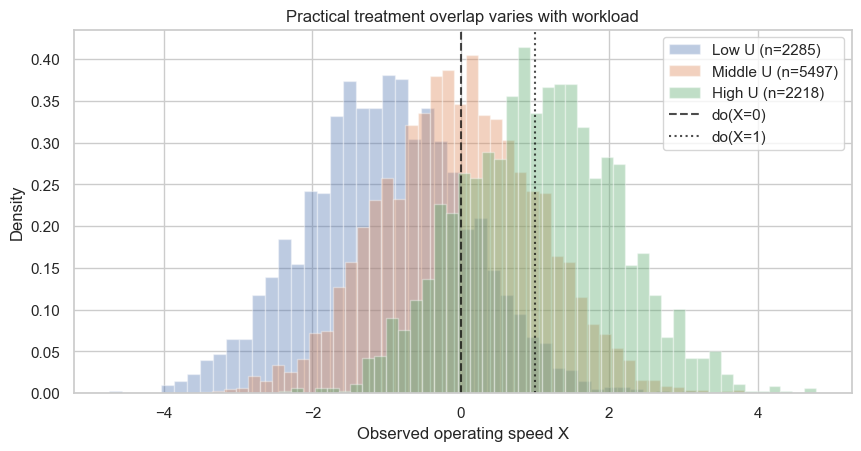

Max factual-outcome consistency error: 0
Empirical disturbance correlation (diagnostic only): 0.0145


In [16]:
# Concrete checks that are possible in our simulated world.
# Consistency, every observed Y equals the potential outcome evaluated at its factual X.
check_df = generate_observational(10_000, "A", seed=9901)
y_factual = structural_outcome(check_df["X"].to_numpy(), check_df["U"].to_numpy(),
                               check_df["epsilon_Y"].to_numpy())
consistency_error = float(jnp.max(jnp.abs(check_df["Y"].to_numpy() - y_factual)))
assert_allclose(check_df["Y"], y_factual, rtol=1e-12, atol=1e-12)

# Independent noise, the simulation generator is designed for independence.
# The empirical correlation is merely a diagnostic, NOT proof of exchangeability.
noise_corr = float(jnp.corrcoef(jnp.asarray(check_df["epsilon_X"]), jnp.asarray(check_df["epsilon_Y"]))[0, 1])

# Practical overlap, show the distribution of speeds in three workload bins.
check_df["workload_group"] = pd.cut(check_df["U"], [-jnp.inf, -0.75, 0.75, jnp.inf],
                                  labels=["Low U", "Middle U", "High U"])
fig, ax = plt.subplots(figsize=(8.5, 4.4), constrained_layout=True)
for group, part in check_df.groupby("workload_group", observed=True):
    ax.hist(part["X"], bins=45, density=True, alpha=0.37, label=f"{group} (n={len(part)})")
ax.axvline(0, linestyle="--", color="black", alpha=0.7, label="do(X=0)")
ax.axvline(1, linestyle=":", color="black", alpha=0.7, label="do(X=1)")
ax.set(xlabel="Observed operating speed X", ylabel="Density",
       title="Practical treatment overlap varies with workload")
ax.legend()
fig.savefig(FIGURES / "07_conditional_speed_overlap.png", dpi=170, bbox_inches="tight")
plt.show()
print(f"Max factual-outcome consistency error: {consistency_error:.3g}")
print(f"Empirical disturbance correlation (diagnostic only): {noise_corr:.4f}")

---
# Causal benchmark

**Scientific objective.** Separate three causal difficulties: functional misspecification, non-identifiability from observed variables, and finite-sample instability due to weak overlap. We reuse the original model as **S0**, and change one aspect at a time. 

**Independent exogenous noise** is used for $U$, treatment assignment, outcomes, and workload measurement. All samples are generated with JAX PRNG keys. The *oracle* files contain true confounders and potential outcomes **only for evaluation**; *observed* files define what a future learner may use. No experimental results are claimed until checks run.

| Scenario | Intervention effect for $do(X=1)$ vs $do(X=0)$ | Observed learner inputs | Identification under stated assumptions |
|---|---|---|---|
| S0 baseline | $2+0.5U$ | $U,X,Y$ | Backdoor via $U$ |
| S1 nonlinear outcome | $2.3+0.6\sin(1)+0.5U$ | $U,X,Y$ | Backdoor via $U$ |
| S2 distribution shift | $2+0.5U$ | $U,X,Y$ and environment | Within each environment via $U$ |
| S3 hidden confounder | $2+0.5U$ | $X,Y$ | **Not generally identifiable** without additional assumptions |
| S4 noisy proxy | $2+0.5U$ | $W,X,Y$ | $W$ alone not generally sufficient when noisy |
| S5 poor overlap | $2+0.5U$ | $U,X,Y$ | Theoretically identified for $\sigma_X>0$, potentially unstable empirically |

The machine/energy story is **illustrative**, not a calibrated physical model.

In [28]:
from dataclasses import dataclass, asdict
import math
import numpy as np  # DataFrame interoperability and Matplotlib inputs only; causal computation uses jax.numpy

ADVANCED = OUTPUT / "advanced"
ADV_DATA = ADVANCED / "data"
ADV_FIG = ADVANCED / "figures"
ADV_REPORT = ADVANCED / "reports"
for p in (ADV_DATA, ADV_FIG, ADV_REPORT): p.mkdir(parents=True, exist_ok=True)

@dataclass(frozen=True)
class AdvancedConfig:
    scenario: str
    environment: str = "A"
    mu_u: float = 0.0
    sigma_u: float = 1.0
    sigma_x: float = 1.0
    sigma_w: float = 0.0
    nonlinear: bool = False

CONFIGS = [
    AdvancedConfig("S0_baseline"),
    AdvancedConfig("S1_nonlinear", nonlinear=True),
    AdvancedConfig("S2_shift", environment="A", mu_u=0.0, sigma_u=1.0),
    AdvancedConfig("S2_shift", environment="B", mu_u=2.0, sigma_u=1.0),
    AdvancedConfig("S2_shift", environment="C", mu_u=0.0, sigma_u=2.0),
    AdvancedConfig("S3_hidden"),
    AdvancedConfig("S4_proxy", sigma_w=0.0),
    AdvancedConfig("S4_proxy", sigma_w=0.5),
    AdvancedConfig("S4_proxy", sigma_w=1.5),
    AdvancedConfig("S5_overlap", sigma_x=1.0),
    AdvancedConfig("S5_overlap", sigma_x=0.3),
    AdvancedConfig("S5_overlap", sigma_x=0.05),
]

def config_name(c):
    return (f"{c.scenario}__{c.environment}"
            + (f"__w{c.sigma_w:g}" if c.scenario == "S4_proxy" else "")
            + (f"__x{c.sigma_x:g}" if c.scenario == "S5_overlap" else ""))

print("Advanced configurations:", len(CONFIGS))

Advanced configurations: 12


## Shared SCM, interventions and ground truth

For $U\sim N(\mu_e,\sigma_e^2)$, $X=0.8U+\sigma_X\epsilon_X$ and
$$Y=2X+1.5U+0.5XU+\epsilon_Y+\mathbf{1}_{S1}\{0.3X^2+0.6\sin(X)\},$$
where all underlying standard-normal errors are independent. For any $x$,
$$Y(x)=2x+1.5U+0.5xU+\epsilon_Y+\mathbf{1}_{S1}\{0.3x^2+0.6\sin(x)\}.$$
For $x_0=0,x_1=1$, $\mathrm{ITE}=2+0.5U+\mathbf{1}_{S1}\{0.3+0.6\sin(1)\}$ and $\mathrm{ATE}_e=2+0.5\mu_e+\mathbf{1}_{S1}\{0.3+0.6\sin(1)\}$. For arbitrary $x$, the interventional expectation is $2x+(1.5+0.5x)\mu_e+\mathbf{1}_{S1}\{0.3x^2+0.6\sin(x)\}$.

**Consistency check:** the same $\epsilon_Y$ is used in factual and counterfactual outcomes. **Confounding:** $U$ is hidden only from *learner* columns in S3; the simulator always knows it. **Proxy:** in S4, $W=U+\sigma_W\epsilon_W$ (when $\sigma_W=0$, $W=U$).

In [18]:
def structural_y_adv(x, u, epsilon_y, c):
    x = jnp.asarray(x, dtype=jnp.float64)
    y = 2*x + 1.5*u + 0.5*x*u + epsilon_y
    if c.nonlinear:
        y = y + 0.3*jnp.square(x) + 0.6*jnp.sin(x)
    return y

def analytical_ate(c):
    return 2.0 + 0.5*c.mu_u + (0.3 + 0.6*math.sin(1.0) if c.nonlinear else 0.0)

def analytical_do_mean(x, c):
    x = jnp.asarray(x, dtype=jnp.float64)
    base = 2*x + (1.5 + 0.5*x)*c.mu_u
    return base + (0.3*x**2 + 0.6*jnp.sin(x) if c.nonlinear else 0.0)

def generate_advanced(key, n, c):
    if n < 1 or c.sigma_u <= 0 or c.sigma_x <= 0 or c.sigma_w < 0:
        raise ValueError("n must be positive; sigma_u and sigma_x > 0; sigma_w >= 0")
    ku, kx, ky, kw = random.split(key, 4)
    u = c.mu_u + c.sigma_u*random.normal(ku, (n,), dtype=jnp.float64)
    ex = random.normal(kx, (n,), dtype=jnp.float64)
    ey = random.normal(ky, (n,), dtype=jnp.float64)
    ew = random.normal(kw, (n,), dtype=jnp.float64)
    x = 0.8*u + c.sigma_x*ex
    w = u + c.sigma_w*ew
    y = structural_y_adv(x,u,ey,c)
    y0 = structural_y_adv(0.0,u,ey,c)
    y1 = structural_y_adv(1.0,u,ey,c)
    oracle = {"U":u,"X":x,"Y":y,"W":w,
              "epsilon_X":ex,"epsilon_Y":ey,"epsilon_W":ew,
              "Y0":y0,"Y1":y1,"ITE":y1-y0}
    if c.scenario == "S3_hidden": columns = ("X","Y")
    elif c.scenario == "S4_proxy": columns = ("W","X","Y")
    else: columns = ("U","X","Y")
    observed = {k:oracle[k] for k in columns}
    return observed, oracle

def to_frame(d):
    return pd.DataFrame({k:np.asarray(v) for k,v in d.items()})

# Verify factual consistency, potential-outcome contrast and intervention formula.
for i,c in enumerate(CONFIGS):
    obs,oracle = generate_advanced(random.PRNGKey(6000+i), 256, c)
    u,x,ey = (oracle[k] for k in ("U","X","epsilon_Y"))
    assert_allclose(oracle["Y"], structural_y_adv(x,u,ey,c))
    expected_ite = 2+0.5*u + (0.3+0.6*jnp.sin(1.) if c.nonlinear else 0.)
    assert_allclose(oracle["ITE"], expected_ite)
    assert all(k in oracle for k in obs)
print("PASS: structural equations, individual effects, and observation masks for all 12 configurations")

PASS: structural equations, individual effects, and observation masks for all 12 configurations


## Data export 

We generate **independent** train/validation/test samples at sizes **500, 2,000, 10,000** for every configuration, each with a distinct deterministic seed. Files are placed below `jax_outputs/advanced/data/`; **the earlier baseline outputs remain untouched**. For each split the notebook writes `__observed.csv` (learner view) and `__oracle.csv` (evaluation only). A manifest records model settings, sizes, seeds and verification statistics. CSV conversion through Pandas is for serialization only.

In [19]:
SIZES_ADV = (500, 2000, 10000)
SPLITS_ADV = ("train", "validation", "test")
records=[]
for cfg_i,c in enumerate(CONFIGS):
    for n_i,n in enumerate(SIZES_ADV):
        for split_i,split in enumerate(SPLITS_ADV):
            seed = 410000 + 10000*cfg_i + 100*n_i + split_i
            obs, oracle = generate_advanced(random.PRNGKey(seed),n,c)
            name=f"{config_name(c)}__n{n}__{split}"
            op=ADV_DATA/f"{name}__observed.csv"
            tp=ADV_DATA/f"{name}__oracle.csv"
            to_frame(obs).to_csv(op,index=False,float_format="%.17g")
            to_frame(oracle).to_csv(tp,index=False,float_format="%.17g")
            empirical=float(jnp.mean(oracle["ITE"]))
            # Finite-population sample truth differs slightly from population ATE.
            sample_exact=float(jnp.mean(2+0.5*oracle["U"] + (0.3+0.6*jnp.sin(1.) if c.nonlinear else 0.)))
            assert abs(empirical-sample_exact)<1e-10
            records.append({"config":config_name(c), "scenario":c.scenario,"environment":c.environment,
                            "split":split,"n":n,"seed":seed,
                            "population_ate":analytical_ate(c),"sample_ite_mean":empirical,
                            "observed_columns":','.join(obs), "observed_file":str(op),"oracle_file":str(tp),
                            "mu_u":c.mu_u,"sigma_u":c.sigma_u,"sigma_x":c.sigma_x,
                            "sigma_w":c.sigma_w,"nonlinear":c.nonlinear})
manifest_adv=pd.DataFrame(records)
manifest_adv.to_csv(ADVANCED/"dataset_manifest.csv",index=False)
assert len(manifest_adv)==12*3*3
assert len(list(ADV_DATA.glob("*.csv")))==2*len(manifest_adv)
print("Generated",len(manifest_adv),"independent configurations × sizes × splits = 108 paired datasets")
print("Exported",2*len(manifest_adv),"CSV files to",ADV_DATA)
display(manifest_adv.head(8))

Generated 108 independent configurations × sizes × splits = 108 paired datasets
Exported 216 CSV files to jax_outputs\advanced\data


,config,scenario,environment,split,n,seed,population_ate,sample_ite_mean,observed_columns,observed_file,oracle_file,mu_u,sigma_u,sigma_x,sigma_w,nonlinear
0,S0_baseline__A,S0_baseline,A,train,500,410000,2.0,2.031092,"U,X,Y",jax_outputs\advanced\data\S0_baseline__A__n500...,jax_outputs\advanced\data\S0_baseline__A__n500...,0.0,1.0,1.0,0.0,False
1,S0_baseline__A,S0_baseline,A,validation,500,410001,2.0,1.992587,"U,X,Y",jax_outputs\advanced\data\S0_baseline__A__n500...,jax_outputs\advanced\data\S0_baseline__A__n500...,0.0,1.0,1.0,0.0,False
2,S0_baseline__A,S0_baseline,A,test,500,410002,2.0,2.024915,"U,X,Y",jax_outputs\advanced\data\S0_baseline__A__n500...,jax_outputs\advanced\data\S0_baseline__A__n500...,0.0,1.0,1.0,0.0,False
3,S0_baseline__A,S0_baseline,A,train,2000,410100,2.0,2.013991,"U,X,Y",jax_outputs\advanced\data\S0_baseline__A__n200...,jax_outputs\advanced\data\S0_baseline__A__n200...,0.0,1.0,1.0,0.0,False
4,S0_baseline__A,S0_baseline,A,validation,2000,410101,2.0,2.002172,"U,X,Y",jax_outputs\advanced\data\S0_baseline__A__n200...,jax_outputs\advanced\data\S0_baseline__A__n200...,0.0,1.0,1.0,0.0,False
5,S0_baseline__A,S0_baseline,A,test,2000,410102,2.0,2.005275,"U,X,Y",jax_outputs\advanced\data\S0_baseline__A__n200...,jax_outputs\advanced\data\S0_baseline__A__n200...,0.0,1.0,1.0,0.0,False
6,S0_baseline__A,S0_baseline,A,train,10000,410200,2.0,2.005031,"U,X,Y",jax_outputs\advanced\data\S0_baseline__A__n100...,jax_outputs\advanced\data\S0_baseline__A__n100...,0.0,1.0,1.0,0.0,False
7,S0_baseline__A,S0_baseline,A,validation,10000,410201,2.0,1.998301,"U,X,Y",jax_outputs\advanced\data\S0_baseline__A__n100...,jax_outputs\advanced\data\S0_baseline__A__n100...,0.0,1.0,1.0,0.0,False


## Interventional verification (fixed treatment and common background variables)

The intervention $do(X=x)$ replaces the assignment equation and preserves the background $U,\epsilon_Y$. Paired comparison at $x=0$ and $x=1$ uses identical backgrounds, reducing Monte Carlo noise. We report numerical error against population analytical expectation; it should be small but not necessarily zero. We also plot the **true intervention mean** for different environments and for the nonlinear response.

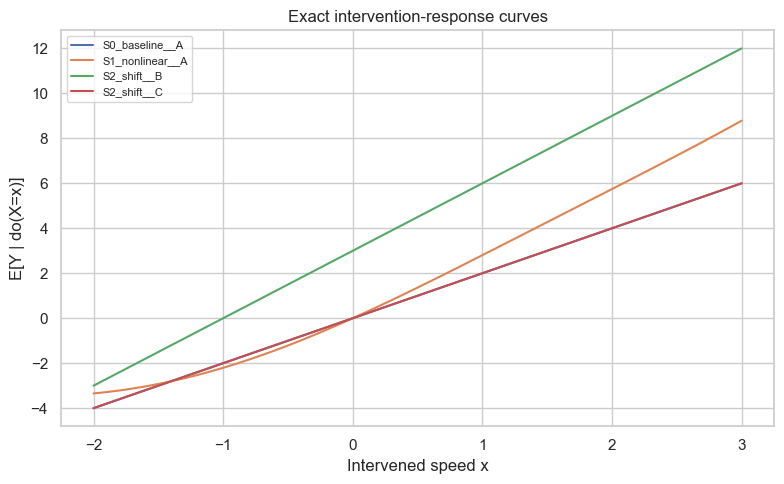

Largest intervention Monte Carlo error: 0.03154


,config,do_x,empirical_mean,analytical_mean,abs_error
0,S0_baseline__A,0.0,0.021571,0.000000,0.021571
1,S0_baseline__A,1.0,2.026761,2.000000,0.026761
2,S1_nonlinear__A,0.0,-0.016216,0.000000,0.016216
3,S1_nonlinear__A,1.0,2.781808,2.804883,0.023074
4,S2_shift__A,0.0,-0.014325,0.000000,0.014325
5,S2_shift__A,1.0,1.982393,2.000000,0.017607
6,S2_shift__B,0.0,3.005890,3.000000,0.005890
7,S2_shift__B,1.0,6.007665,6.000000,0.007665
8,S2_shift__C,0.0,-0.013965,0.000000,0.013965
9,S2_shift__C,1.0,1.982285,2.000000,0.017715


In [20]:
intervention_records=[]
XGRID=jnp.linspace(-2.,3.,51)
N_INTERV=20000
for ci,c in enumerate(CONFIGS):
    _, oracle = generate_advanced(random.PRNGKey(720000+ci),N_INTERV,c)
    u,ey=oracle["U"],oracle["epsilon_Y"]
    for xval in [0.,1.]:
        y_do=structural_y_adv(xval,u,ey,c)
        intervention_records.append({"config":config_name(c),"do_x":xval,
            "empirical_mean":float(jnp.mean(y_do)),"analytical_mean":float(analytical_do_mean(xval,c)),
            "abs_error":abs(float(jnp.mean(y_do)-analytical_do_mean(xval,c)))})
intervention_df=pd.DataFrame(intervention_records)
intervention_df.to_csv(ADV_REPORT/"intervention_verification.csv",index=False)
# Use a tolerance appropriate for 20k Monte Carlo draws, not exact equality.
assert intervention_df.abs_error.max() < 0.12, "MC error exceeds the documented tolerance"
fig,ax=plt.subplots(figsize=(8,5))
for c in [CONFIGS[0],CONFIGS[1],CONFIGS[3],CONFIGS[4]]:
    ax.plot(np.asarray(XGRID),np.asarray(analytical_do_mean(XGRID,c)),label=config_name(c))
ax.set(xlabel="Intervened speed x",ylabel="E[Y | do(X=x)]",title="Exact intervention-response curves")
ax.legend(fontsize=8);fig.tight_layout();fig.savefig(ADV_FIG/"01_intervention_responses.png",dpi=160);plt.show()
print("Largest intervention Monte Carlo error:",round(intervention_df.abs_error.max(),5))
display(intervention_df)

## population shift

For fixed $U=u$, $\mathrm{CATE}(u)=2+0.5u$ is invariant across environments. Because $U$ shifts, $\mathrm{ATE}_e=2+0.5\mu_e$ changes for environment B. The variance-only shift in environment C does **not** change this ATE, though the workload and outcome distributions change. This demonstrates **population-level effect heterogeneity**, not structural mechanism drift.

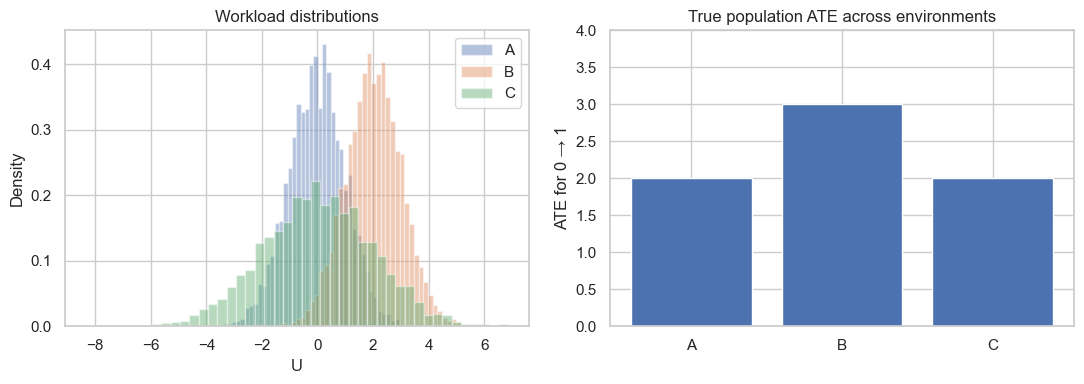

{'A': 2.0, 'B': 3.0, 'C': 2.0}


In [21]:
fig,axes=plt.subplots(1,2,figsize=(11,4))
shift_cs=[c for c in CONFIGS if c.scenario=="S2_shift"]
for i,c in enumerate(shift_cs):
    o,t=generate_advanced(random.PRNGKey(8400+i),5000,c)
    axes[0].hist(np.asarray(t["U"]),bins=45,alpha=.42,density=True,label=c.environment)
axes[0].set(title="Workload distributions",xlabel="U",ylabel="Density");axes[0].legend()
axes[1].bar([c.environment for c in shift_cs],[analytical_ate(c) for c in shift_cs])
axes[1].set(title="True population ATE across environments",ylabel="ATE for 0 → 1",ylim=(0,4))
fig.tight_layout();fig.savefig(ADV_FIG/"02_environment_shift.png",dpi=160);plt.show()
print({c.environment: analytical_ate(c) for c in shift_cs})

## hidden confounding

The observed file contains only $(X,Y)$, and $U$ is hidden. The backdoor formula that adjusts for $U$ cannot be used from those columns. **Non-identification is a property of the observed data together with the allowed model class**, not something established by an empirical correlation.

To make this concrete, consider two *Gaussian linear* SCMs with the **same bivariate observational $(X,Y)$ distribution**. Model A generates $X=\epsilon_X$, $Y=aX+\epsilon_Y$ ($a=1$), so the causal slope is 1. Model B generates $X=U+\epsilon_X$, $Y=bU+\epsilon_Y$ with $U\sim N(0,1)$, $\mathrm{Var}(\epsilon_X)=1$ and $b=2$, and selects outcome noise variance to match observational covariance. A convenient match uses instead Model A with $X\sim N(0,2)$, $Y=X+\eta$, $\eta\sim N(0,4)$, and Model B with $X=U+\epsilon_X$, $Y=2U+\epsilon_Y$, $\mathrm{Var}(\epsilon_Y)=2$. Both have $\mathrm{Var}(X)=2$, $\mathrm{Cov}(X,Y)=2$, $\mathrm{Var}(Y)=6$, but causal $\partial E[Y\mid do(X=x)]/\partial x$ is respectively **1** and **0**. These two SCMs are illustrative countermodels; they are **not** the six-scenario generating equations.

In [22]:
# Exact observational moments for two distinct causal explanations.
# Model A: X ~ N(0,2), Y = X + eta, eta ~ N(0,4)
# Model B: X = U + ex, Y = 2U + ey, independent standard U/ex, Var(ey)=2
moments_A=jnp.array([[2.,2.],[2.,6.]])
moments_B=jnp.array([[1.+1.,2.],[2.,4.+2.]])
assert_allclose(moments_A,moments_B)
assert 1.0 != 0.0
print("Observed covariance matrices agree exactly:", np.asarray(moments_A))
print("But causal slopes differ: 1 (Model A) versus 0 (Model B).")
example_hidden=next(c for c in CONFIGS if c.scenario=="S3_hidden")
obs,oracle=generate_advanced(random.PRNGKey(90100),1000,example_hidden)
assert set(obs)=={"X","Y"} and "U" in oracle
print("Observed learner columns:",list(obs),"; oracle-only columns include hidden U, Y0, Y1, ITE.")

Observed covariance matrices agree exactly: [[2. 2.]
 [2. 6.]]
But causal slopes differ: 1 (Model A) versus 0 (Model B).
Observed learner columns: ['X', 'Y'] ; oracle-only columns include hidden U, Y0, Y1, ITE.


## proxy quality

$W=U+\sigma_W\epsilon_W$. When $\sigma_W=0$, conditioning on $W$ is equivalent to conditioning on $U$. For nonzero noise, $W$ is only an imperfect proxy, and adjustment for $W$ alone generally does not satisfy the original backdoor condition.

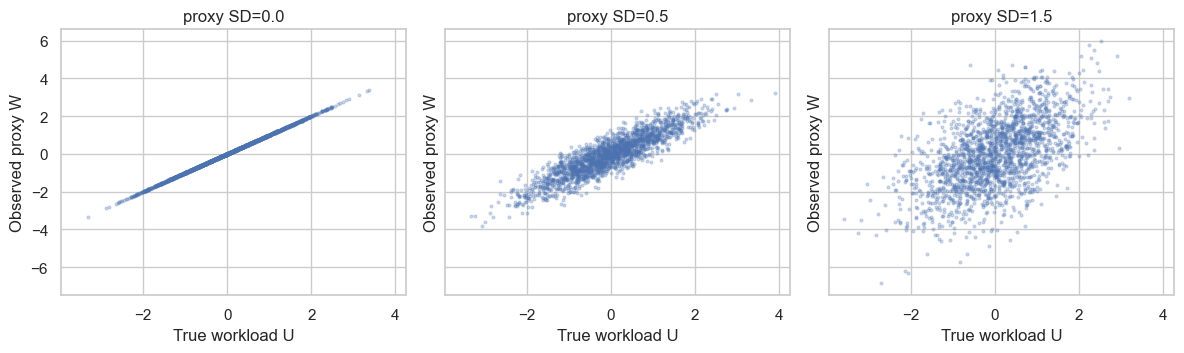

,sigma_w,correlation_U_W,proxy_RMSE
0,0.0,1.000000,0.000000
1,0.5,0.891906,0.498304
2,1.5,0.558005,1.498628


In [23]:
proxy_cs=[c for c in CONFIGS if c.scenario=="S4_proxy"]
proxy_rows=[]
fig,axes=plt.subplots(1,3,figsize=(12,3.7),sharex=True,sharey=True)
for i,(ax,c) in enumerate(zip(axes,proxy_cs)):
    obs,truth=generate_advanced(random.PRNGKey(93000+i),2000,c)
    corr=float(jnp.corrcoef(jnp.stack([truth["U"],truth["W"]]))[0,1])
    rmse=float(jnp.sqrt(jnp.mean((truth["W"]-truth["U"])**2)))
    proxy_rows.append({"sigma_w":c.sigma_w,"correlation_U_W":corr,"proxy_RMSE":rmse})
    ax.scatter(np.asarray(truth["U"]),np.asarray(truth["W"]),s=4,alpha=.25)
    ax.set(title=f"proxy SD={c.sigma_w}",xlabel="True workload U",ylabel="Observed proxy W")
fig.tight_layout();fig.savefig(ADV_FIG/"03_proxy_quality.png",dpi=160);plt.show()
proxy_df=pd.DataFrame(proxy_rows);proxy_df.to_csv(ADV_REPORT/"proxy_diagnostics.csv",index=False)
display(proxy_df)
assert proxy_df.proxy_RMSE.iloc[0]<1e-12
assert proxy_df.proxy_RMSE.iloc[-1]>proxy_df.proxy_RMSE.iloc[1]

## treatment overlap

$X\mid U=u\sim N(0.8u,\sigma_X^2)$. This density is positive for all finite $x,u$ when $\sigma_X>0$; therefore strict positivity is not violated. But as $\sigma_X\to0$, treatment levels away from $0.8u$ have very low probability, producing **weak practical overlap**. For transparency we compute the share of observations with $|X-1|<0.2$ within the $U\in[-0.5,0.5]$ subgroup, in addition to a scatterplot. The diagnostic is descriptive, not a hypothesis test.

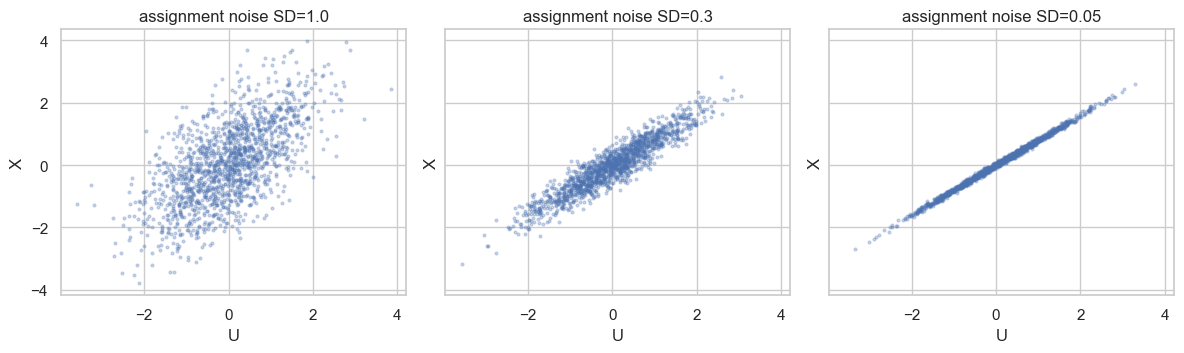

,sigma_x,n_subgroup,fraction_X_near_1
0,1.00,4570,0.096499
1,0.30,4571,0.012689
2,0.05,4549,0.000000


In [24]:
overlap_cs=[c for c in CONFIGS if c.scenario=="S5_overlap"]
overlap_rows=[]
fig,axes=plt.subplots(1,3,figsize=(12,3.7),sharex=True,sharey=True)
for i,(ax,c) in enumerate(zip(axes,overlap_cs)):
    obs,truth=generate_advanced(random.PRNGKey(99000+i),12000,c)
    u,x=truth["U"],truth["X"]
    subgroup=jnp.abs(u)<0.5
    prob=float(jnp.mean((jnp.abs(x[subgroup]-1.0)<0.2).astype(jnp.float64)))
    overlap_rows.append({"sigma_x":c.sigma_x,"n_subgroup":int(jnp.sum(subgroup)),"fraction_X_near_1":prob})
    ax.scatter(np.asarray(u[:1500]),np.asarray(x[:1500]),s=4,alpha=.28)
    ax.set(title=f"assignment noise SD={c.sigma_x}",xlabel="U",ylabel="X")
fig.tight_layout();fig.savefig(ADV_FIG/"04_treatment_overlap.png",dpi=160);plt.show()
overlap_df=pd.DataFrame(overlap_rows)
overlap_df.to_csv(ADV_REPORT/"overlap_diagnostics.csv",index=False)
display(overlap_df)
assert overlap_df.fraction_X_near_1.iloc[-1] < overlap_df.fraction_X_near_1.iloc[0]

## reproducibility

| Scenario | Oracle effect known? | Identified from learner view under stated assumptions? | Caveat |
|---|---|---|---|
| S0 | Yes | Yes ($U$ adjustment) | Functional form still matters to estimation |
| S1 | Yes | Yes ($U$ adjustment) | Nonlinear intervention response |
| S2 | Yes | Yes in each environment ($U$ adjustment) | Transporting ATE requires target $p_e(U)$ |
| S3 | Yes | Generally no | Hidden $U$, no extra identification assumptions |
| S4, $\sigma_W=0$ | Yes | Yes ($W=U$) | Perfect proxy |
| S4, $\sigma_W>0$ | Yes | Not guaranteed by proxy backdoor adjustment | Additional measurement models could help |
| S5, $\sigma_X>0$ | Yes | Yes in principle | Practical finite-sample positivity is weak |



In [26]:
# Final audit of exports and run metadata.
assert manifest_adv.observed_file.map(lambda p:Path(p).exists()).all()
assert manifest_adv.oracle_file.map(lambda p:Path(p).exists()).all()
assert manifest_adv.groupby("config").size().eq(9).all()
for _,r in manifest_adv.iterrows():
    observed_df=pd.read_csv(r.observed_file)
    oracle_df=pd.read_csv(r.oracle_file)
    assert len(observed_df)==len(oracle_df)==r.n
    assert not observed_df.isna().any().any()
    assert set(observed_df.columns)==set(r.observed_columns.split(','))
    assert {'U','Y0','Y1','ITE','epsilon_X','epsilon_Y'}.issubset(oracle_df.columns)
    assert np.allclose(oracle_df['Y1']-oracle_df['Y0'],oracle_df['ITE'],rtol=1e-12,atol=1e-12)
metadata={"benchmark":"Advanced causal identifiability benchmark",
          "library":"JAX","jax_version":jax.__version__,"jax_device":str(jax.devices()[0]),
          "model":"U -> X, U -> Y, X -> Y; proxy W <- U",
          "design":"fixed scenario parameters, independent JAX keys per config/size/split",
          "sample_sizes":list(SIZES_ADV),"splits":list(SPLITS_ADV),
          "configurations":[asdict(c) for c in CONFIGS],
          "note":"Oracle files are not learner training inputs."}
with open(ADVANCED/"benchmark_metadata.json","w") as f:json.dump(metadata,f,indent=2)
summary={"configurations":len(CONFIGS),"dataset_pairs":len(manifest_adv),
         "csv_files":2*len(manifest_adv),"figures":len(list(ADV_FIG.glob('*.png'))),
         "max_intervention_MC_abs_error":float(intervention_df.abs_error.max())}
with open(ADV_REPORT/"verification_summary.json","w") as f:json.dump(summary,f,indent=2)
print("ALL ADVANCED CHECKS PASSED")
print(json.dumps(summary,indent=2))


ALL ADVANCED CHECKS PASSED
{
  "configurations": 12,
  "dataset_pairs": 108,
  "csv_files": 216,
  "figures": 4,
  "max_intervention_MC_abs_error": 0.03154040636036881
}
